In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score, RocCurveDisplay

sns.set_theme(style="darkgrid")
print(f"PyTorch version: {torch.__version__} ✅")
print(f"GPU available: {torch.cuda.is_available()}")

PyTorch version: 2.11.0+cpu ✅
GPU available: False


In [3]:
cols = ['label',
        'lepton_pT', 'lepton_eta', 'lepton_phi',
        'missing_energy_magnitude', 'missing_energy_phi',
        'jet1pt', 'jet1eta', 'jet1phi', 'jet1b_tag',
        'jet2pt', 'jet2eta', 'jet2phi', 'jet2b_tag',
        'jet3pt', 'jet3eta', 'jet3phi', 'jet3b_tag',
        'jet4pt', 'jet4eta', 'jet4phi', 'jet4b_tag',
        'mjj', 'mjjj', 'mlv', 'mjlv', 'mbb', 'mwbb', 'mwwbb']

df = pd.read_csv('../data/HIGGS.csv', header=None, names=cols, nrows=500000)

X = df.drop('label', axis=1).values
y = df['label'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

print(f"Train: {X_train.shape[0]} rows ✅")
print(f"Test:  {X_test.shape[0]} rows ✅")

Train: 400000 rows ✅
Test:  100000 rows ✅


In [4]:
# detect GPU, fall back to CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

X_train_t = torch.FloatTensor(X_train).to(device)
y_train_t = torch.FloatTensor(y_train).to(device)
X_test_t  = torch.FloatTensor(X_test).to(device)
y_test_t  = torch.FloatTensor(y_test).to(device)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader  = DataLoader(train_dataset, batch_size=1024, shuffle=True)

print(f"Batches per epoch: {len(train_loader)} ✅")

Using device: cpu
Batches per epoch: 391 ✅


In [5]:
class HiggsNet(nn.Module):
    def __init__(self):
        super(HiggsNet, self).__init__()
        
        self.network = nn.Sequential(
            # input layer: 28 features
            nn.Linear(28, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            # hidden layer 1
            nn.Linear(256, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            # hidden layer 2
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            # hidden layer 3
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            
            # output: single probability
            nn.Linear(64, 1),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        return self.network(x).squeeze()

model = HiggsNet().to(device)
print(model)
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}")

HiggsNet(
  (network): Sequential(
    (0): Linear(in_features=28, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=128, out_features=64, bias=True)
    (13): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
    (15): Linear(in_features=64, out_features=1, bias=True)
    (16): Sigmoid()
  )
)

Total parameters: 115,841


In [7]:
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', patience=3, factor=0.5
)

print("Optimizer and loss ready ✅")

Optimizer and loss ready ✅


In [12]:
epochs = 30
train_losses = []
val_aucs = []

for epoch in range(epochs):
    # --- training ---
    model.train()
    total_loss = 0
    
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    
    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)
    
    # --- validation ---
    model.eval()
    with torch.no_grad():
        y_prob = model(X_test_t).cpu().numpy()
    
    auc = roc_auc_score(y_test, y_prob)
    val_aucs.append(auc)
    scheduler.step(auc)
    
    print(f"Epoch {epoch+1:02d}/{epochs} | Loss: {avg_loss:.4f} | AUC: {auc:.4f}")

print("\nTraining complete ✅")

Epoch 01/30 | Loss: 0.5118 | AUC: 0.8328
Epoch 02/30 | Loss: 0.5107 | AUC: 0.8327
Epoch 03/30 | Loss: 0.5100 | AUC: 0.8332
Epoch 04/30 | Loss: 0.5093 | AUC: 0.8335
Epoch 05/30 | Loss: 0.5084 | AUC: 0.8350
Epoch 06/30 | Loss: 0.5084 | AUC: 0.8347
Epoch 07/30 | Loss: 0.5074 | AUC: 0.8351
Epoch 08/30 | Loss: 0.5065 | AUC: 0.8350
Epoch 09/30 | Loss: 0.5064 | AUC: 0.8349
Epoch 10/30 | Loss: 0.5037 | AUC: 0.8363
Epoch 11/30 | Loss: 0.5026 | AUC: 0.8369
Epoch 12/30 | Loss: 0.5023 | AUC: 0.8369
Epoch 13/30 | Loss: 0.5011 | AUC: 0.8375
Epoch 14/30 | Loss: 0.5012 | AUC: 0.8376
Epoch 15/30 | Loss: 0.5007 | AUC: 0.8376
Epoch 16/30 | Loss: 0.5005 | AUC: 0.8379
Epoch 17/30 | Loss: 0.5000 | AUC: 0.8377
Epoch 18/30 | Loss: 0.4998 | AUC: 0.8379
Epoch 19/30 | Loss: 0.4998 | AUC: 0.8380
Epoch 20/30 | Loss: 0.4995 | AUC: 0.8377
Epoch 21/30 | Loss: 0.4993 | AUC: 0.8381
Epoch 22/30 | Loss: 0.4988 | AUC: 0.8382
Epoch 23/30 | Loss: 0.4981 | AUC: 0.8387
Epoch 24/30 | Loss: 0.4981 | AUC: 0.8387
Epoch 25/30 | Lo

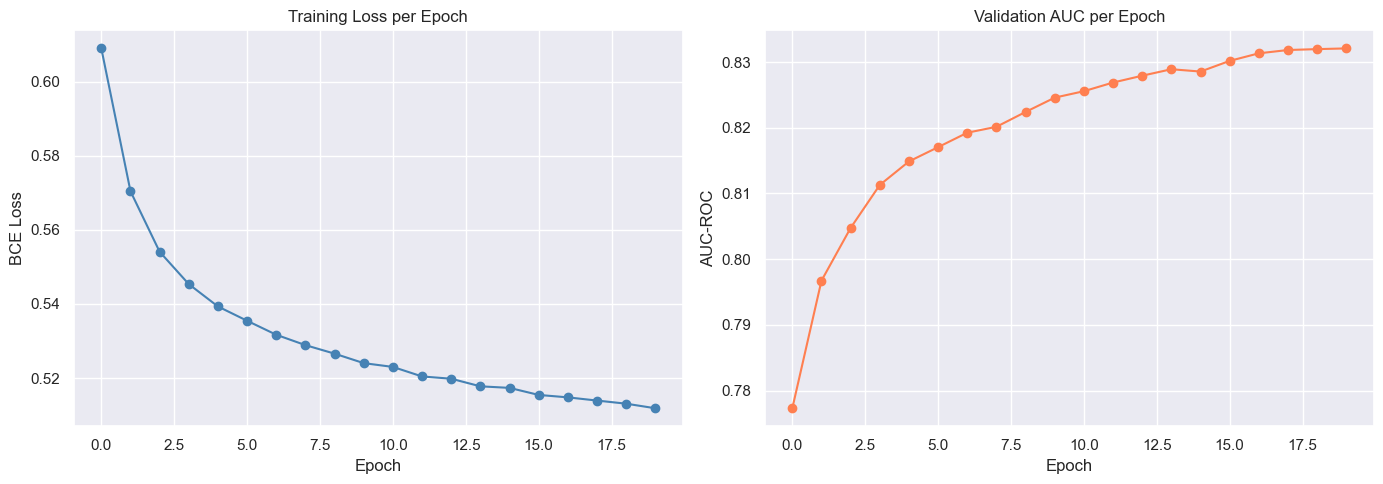

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, color='steelblue', marker='o')
ax1.set_title('Training Loss per Epoch')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('BCE Loss')

ax2.plot(val_aucs, color='coral', marker='o')
ax2.set_title('Validation AUC per Epoch')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('AUC-ROC')

plt.tight_layout()
plt.savefig('../plots/nn_training_history.png', dpi=150)
plt.show()

In [11]:
model.eval()
with torch.no_grad():
    y_prob = model(X_test_t).cpu().numpy()

y_pred = (y_prob >= 0.5).astype(int)

nn_auc = roc_auc_score(y_test, y_prob)
nn_acc = accuracy_score(y_test, y_pred)

print(f"Neural Network")
print(f"  Accuracy : {nn_acc:.4f}")
print(f"  AUC-ROC  : {nn_auc:.4f}")

Neural Network
  Accuracy : 0.7477
  AUC-ROC  : 0.8321
